# 10 · Proyecto final con un caso real: inspección visual de defectos

Todos los notebooks anteriores usaban datos generados en el propio notebook o incluidos en una biblioteca, así que los resultados eran exactos y las ejecuciones, cortas. Este proyecto final usa **fotografías reales de una línea de producción real**, y se aborda como lo haría un equipo en una competición de ciencia de datos: un enunciado por escrito, una métrica fijada de antemano, un conjunto de prueba que permanece bloqueado hasta el final y una tabla de clasificación con cada intento.

**El caso.** Al final de una línea de fabricación, cada álabe terminado se fotografía antes de embalarlo. Hoy un inspector mira cada foto y clasifica el álabe en uno de tres contenedores:

| Clase | Significado | Qué pasa con la pieza |
|---|---|---|
| **Good** (buena) | sin defecto visible | se envía |
| **Nick** (mella) | una pequeña abolladura o desportilladura, normalmente en un borde | se rechaza |
| **Scratch** (arañazo) | una línea fina marcada en la superficie | se rechaza |

Las clases conservan en el código sus nombres en inglés (Good, Nick, Scratch) porque son los nombres de las carpetas del conjunto de datos.

Automatizar esta comprobación es uno de los trabajos de visión artificial más habituales en la industria: la cámara nunca se cansa, cada decisión queda registrada y el tiempo del inspector se dedica solo a los casos dudosos. La dificultad es la que aparece en casi todos los proyectos reales: **muy pocos datos etiquetados** (400 fotos, solo 48 de ellas con mellas), defectos que ocupan una fracción minúscula de la imagen y una estructura de costes en la que dejar pasar una pieza mala es mucho peor que rechazar una buena.

Lo que vas a hacer, y en qué notebook anterior se apoya cada paso:

| Sección | Paso | Se apoya en |
|---|---|---|
| 1-3 | el enunciado, los datos, un primer vistazo | |
| 4 | un conjunto de prueba bloqueado y validación cruzada | 03 (entrenamiento/validación/prueba) |
| 5 | referencias: clase mayoritaria y características de imagen hechas a mano | 03 (supera siempre una referencia) |
| 6 | una CNN entrenada desde cero | 04 |
| 7-8 | aprendizaje por transferencia: características congeladas y después ajuste fino con aumento de datos | 04 (transferencia, aumento de datos, ResNet) |
| 9 | ensamblado y aumento en tiempo de prueba | 03 |
| 10 | convertir probabilidades en una decisión de aceptar o rechazar | 09 (precisión y exhaustividad) |
| 11 | abrir el conjunto de prueba: la clasificación final | |
| 12 | dónde mira el modelo (Grad-CAM) y en qué se equivoca | 03 (análisis de errores) |
| 13 | del notebook a la línea de producción | |

Se ejecuta en una CPU. A diferencia de los demás módulos, la primera vez necesita dos descargas: las fotos (unos 80 MB) y los pesos de una red preentrenada con ImageNet (unos 45 MB, mediante `torchvision`). Ambas se guardan en caché, así que las ejecuciones siguientes empiezan al instante.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, json, time, hashlib, urllib.request
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, confusion_matrix

torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = False
CLASSES = ["Good", "Nick", "Scratch"]

## 1. El enunciado

Antes de tocar los datos, escribe cómo se va a medir el éxito. Cambiar la métrica después de ver los resultados es la forma más fácil de engañarse a uno mismo.

* **Tarea:** clasificar cada foto como Good, Nick o Scratch.
* **Métrica principal: macro-F1.** La puntuación F1 (media armónica de precisión y exhaustividad, notebook 09) se calcula para cada clase y las tres se promedian con el mismo peso. La exactitud simple premiaría a un modelo que ignora la clase minoritaria Nick: como la mitad de las fotos son Good, "responder siempre Good" ya obtiene alrededor de un 50 %.
* **Métricas operativas**, porque al final la línea solo necesita una decisión de sí o no:
  * **tasa de escape**: proporción de piezas defectuosas que se aceptan como buenas (el error caro: un cliente recibe una pieza dañada);
  * **tasa de falso rechazo**: proporción de piezas buenas que van al contenedor de rechazo (el error barato: la pieza se reinspecciona o se desecha).
* **Reglas:** un 25 % estratificado de las fotos se reserva como **conjunto de prueba** y no se mira hasta la sección 11. Todas las decisiones anteriores (modelo, resolución, umbral) se toman con **validación cruzada de 5 pliegues** sobre el 75 % restante, al que llamamos conjunto de desarrollo.

Las plataformas de competición funcionan igual: la puntuación que ves mientras trabajas se calcula con datos sobre los que puedes ajustar, y la clasificación final usa datos que nadie ha visto. Los equipos que ajustan con demasiado entusiasmo contra la puntuación visible pierden puestos cuando se revela la oculta.

## 2. Los datos

Las fotos son el **GKN Blade Surface Defect Dataset**, publicado por Qianyu Zhou en Mendeley Data (2023, doi:[10.17632/3bh998k78g.1](https://doi.org/10.17632/3bh998k78g.1)) con la licencia **Creative Commons Atribución 4.0**, que permite reutilizarlo citando la fuente. Los mismos archivos están replicados en varios portales públicos de conjuntos de datos; nosotros los descargamos de la publicación original. La celda siguiente pide al repositorio la lista de archivos, descarga cada foto una sola vez y comprueba su huella SHA-256 con la que publica el repositorio, de modo que un archivo dañado o alterado detiene el notebook en lugar de cambiar los resultados en silencio.

In [2]:
API = "https://data.mendeley.com/public-api/datasets/3bh998k78g"
CACHE = os.path.expanduser("~/.cache/nn1001/gkn_blades")      # compartida por todas las ejecuciones de este notebook

def get(url):
    req = urllib.request.Request(url, headers={"User-Agent": "nn1001-course/1.0"})
    with urllib.request.urlopen(req, timeout=60) as r:
        return r.read()

def fetch(f, folders):
    path = os.path.join(CACHE, folders[f["folder_id"]], f["filename"])
    if not os.path.exists(path):
        data = get(f["content_details"]["download_url"])
        if hashlib.sha256(data).hexdigest() != f["content_details"]["sha256_hash"]:
            raise ValueError(f"checksum mismatch for {f['filename']}")
        os.makedirs(os.path.dirname(path), exist_ok=True)
        with open(path, "wb") as out:
            out.write(data)
    return path

meta = json.loads(get(API))
folders = {d["id"]: d["name"] for d in json.loads(get(API + "/folders/1"))}
t0 = time.time()
with ThreadPoolExecutor(8) as pool:
    paths = list(pool.map(lambda f: fetch(f, folders), meta["files"]))
print(f"{meta['name']} (version {meta['version']}), licence: {meta['data_licence']['short_name']}")
print(f"{len(paths)} fotos listas en {CACHE} ({time.time() - t0:.0f} s)")

GKN Blade Surface Defect Dataset (version 1), licence: CC BY 4.0
400 fotos listas en /home/patito/.cache/nn1001/gkn_blades (0 s)


## 3. Un primer vistazo

Cuenta las clases, comprueba el tamaño de las imágenes y mira las fotos con tus propios ojos antes de entrenar nada.

Good      203 fotos (51%)
Nick       48 fotos (12%)
Scratch   149 fotos (37%)
ancho de imagen 892-1430 px, alto 847-1631 px
exactitud de responder siempre 'Good': 50.7%


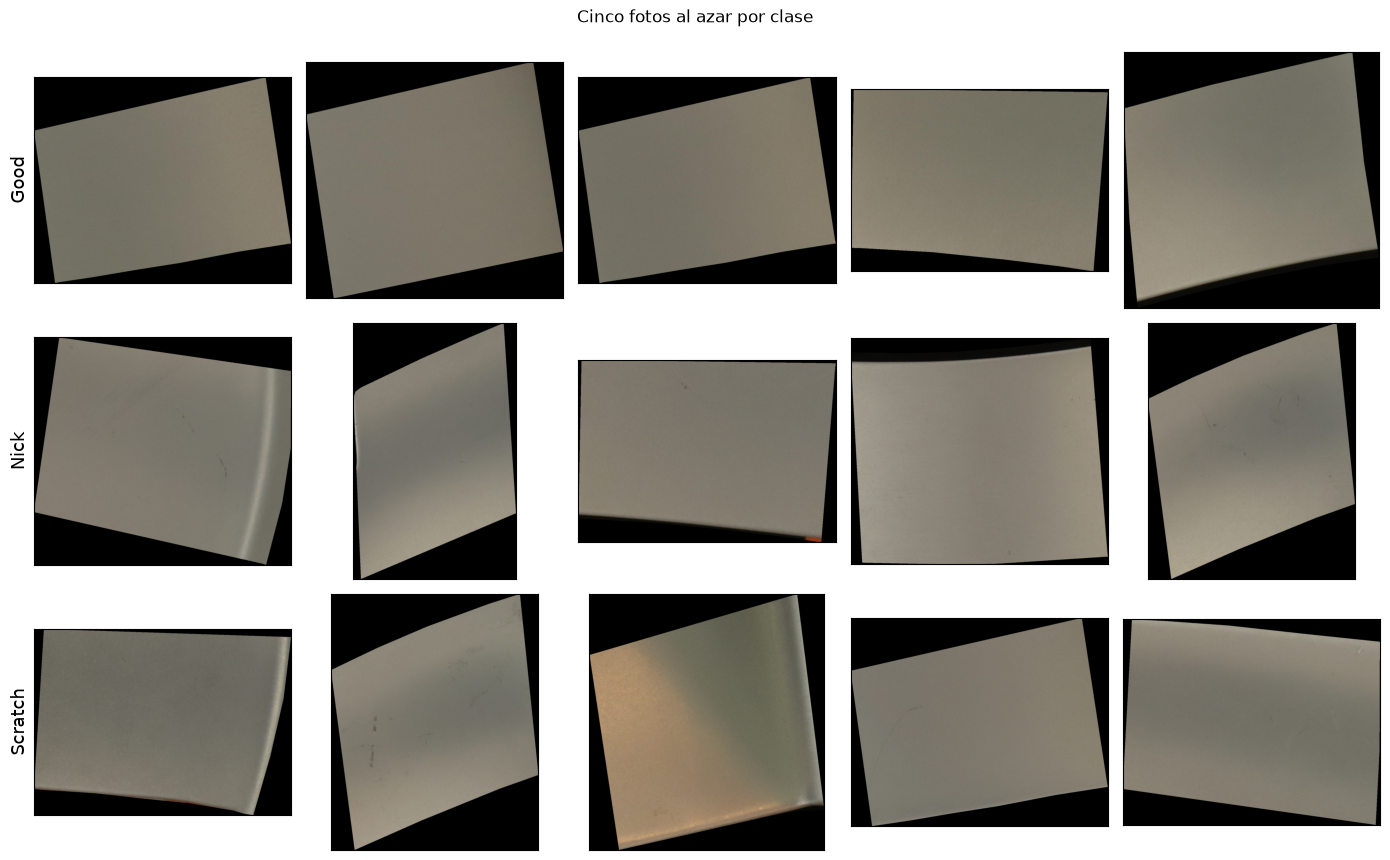

In [3]:
files = sorted(paths)
labels = np.array([CLASSES.index(os.path.basename(os.path.dirname(p))) for p in files])
sizes = np.array([Image.open(p).size for p in files])
for c, name in enumerate(CLASSES):
    print(f"{name:8s} {np.sum(labels == c):4d} fotos ({np.mean(labels == c):.0%})")
print(f"ancho de imagen {sizes[:, 0].min()}-{sizes[:, 0].max()} px, alto {sizes[:, 1].min()}-{sizes[:, 1].max()} px")
print(f"exactitud de responder siempre 'Good': {np.mean(labels == 0):.1%}")

fig, axes = plt.subplots(3, 5, figsize=(14, 8.6))
rng = np.random.default_rng(1)
for c, name in enumerate(CLASSES):
    for k, i in enumerate(rng.choice(np.where(labels == c)[0], 5, replace=False)):
        ax = axes[c, k]; ax.imshow(Image.open(files[i])); ax.set_xticks([]); ax.set_yticks([])
        if k == 0: ax.set_ylabel(name, fontsize=13)
plt.suptitle("Cinco fotos al azar por clase", y=0.995); plt.tight_layout(); plt.show()

Destacan tres cosas, y cada una condiciona el resto del notebook:

1. **Las clases están desbalanceadas**: alrededor de la mitad de las fotos son Good y solo una de cada ocho es Nick. La pérdida de entrenamiento ponderará las clases de forma inversa a su frecuencia, y la métrica es macro-F1.
2. **Las fotos son grandes (aproximadamente entre 850 y 1.650 píxeles de lado), pero los defectos son diminutos.** Una mella ocupa unas pocas decenas de píxeles; un arañazo es una línea tenue. Reducir las fotos a los 224×224 píxeles que espera una CNN estándar hará que algunos defectos sean casi invisibles, así que cabe esperar un techo para lo que cualquier modelo puede alcanzar a esa resolución.
3. **Los álabes están fotografiados con ángulos distintos sobre un fondo negro.** La orientación no aporta información, así que girar y voltear las fotos produce ejemplos de entrenamiento nuevos e igual de válidos (aumento de datos, notebook 04).

El zoom de abajo muestra lo pequeños que son los defectos: cada fila es una foto, primero entera y después un recorte de la zona con el mayor contraste local. Esa regla sencilla encuentra a menudo el defecto, pero no siempre: el segundo arañazo es demasiado tenue para ella, lo que dice mucho de lo difíciles de ver que son estos defectos.

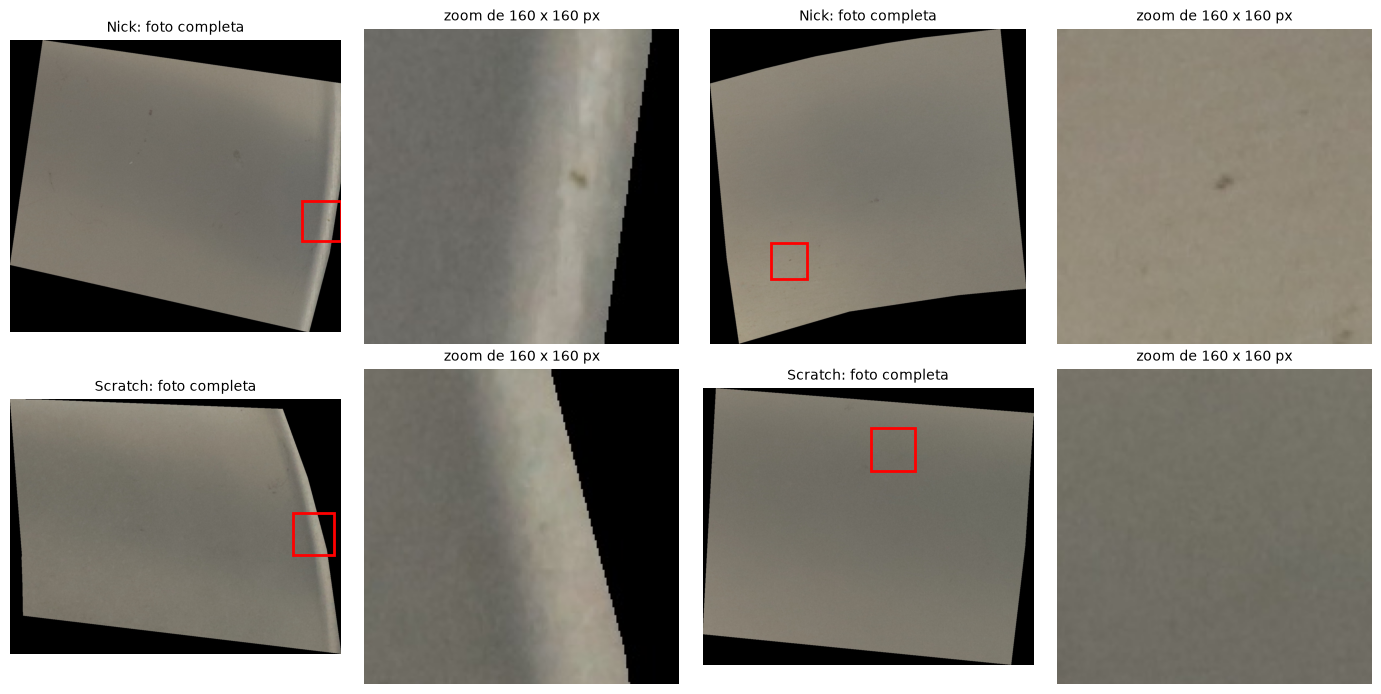

In [4]:
def strongest_patch(img, size=160):
    g = np.asarray(img.convert("L"), dtype=np.float32)
    gy, gx = np.gradient(g)
    mag = np.hypot(gx, gy)
    mask = g > 40                                          # se ignoran el fondo negro y el contorno del álabe
    mask = np.minimum.reduce([np.roll(mask, s, axis=a) for a in (0, 1) for s in (-12, 12)])
    mag = np.where(mask, mag, 0)
    k = 24                                                 # se suma la energía del gradiente en bloques de k x k
    H, W = (mag.shape[0] // k) * k, (mag.shape[1] // k) * k
    blocks = mag[:H, :W].reshape(H // k, k, W // k, k).sum(axis=(1, 3))
    by, bx = np.unravel_index(blocks.argmax(), blocks.shape)
    cy, cx = by * k + k // 2, bx * k + k // 2
    y0, x0 = int(np.clip(cy - size // 2, 0, g.shape[0] - size)), int(np.clip(cx - size // 2, 0, g.shape[1] - size))
    return x0, y0, size

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, c in enumerate([1, 2]):
    for j, i in enumerate(np.where(labels == c)[0][[3, 11]]):
        img = Image.open(files[i]); x0, y0, s = strongest_patch(img)
        ax = axes[row, 2 * j]; ax.imshow(img); ax.add_patch(plt.Rectangle((x0, y0), s, s, fill=False, ec="red", lw=2))
        ax.set_title(f"{CLASSES[c]}: foto completa", fontsize=10); ax.axis("off")
        ax = axes[row, 2 * j + 1]; ax.imshow(img.crop((x0, y0, x0 + s, y0 + s))); ax.set_title("zoom de 160 x 160 px", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. El conjunto de prueba bloqueado y los pliegues de validación cruzada

Cada foto se redimensiona una vez a 224×224 y se normaliza con las medias y desviaciones típicas por canal de ImageNet (la red preentrenada de la sección 7 espera exactamente eso). Después viene la división: un 25 % estratificado como conjunto de prueba, que no se toca hasta la sección 11, y cinco pliegues estratificados sobre el 75 % restante. Todos los modelos de abajo se evalúan con los mismos cinco pliegues, así que sus números son directamente comparables: cada foto de desarrollo recibe una predicción **fuera de pliegue**, hecha por un modelo que nunca la vio.

In [5]:
R = 224
t0 = time.time()
X = np.stack([np.asarray(Image.open(p).convert("RGB").resize((R, R), Image.BILINEAR)) for p in files])
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
XN = (torch.tensor(X).permute(0, 3, 1, 2).float() / 255 - MEAN) / STD
Y = torch.tensor(labels)
print(f"{len(X)} fotos redimensionadas en {time.time() - t0:.0f} s -> tensor {tuple(XN.shape)}")

dev, test = train_test_split(np.arange(len(labels)), test_size=0.25, stratify=labels, random_state=42)
FOLDS = list(StratifiedKFold(5, shuffle=True, random_state=0).split(dev, labels[dev]))
print("desarrollo:", np.bincount(labels[dev]), " prueba (bloqueada):", np.bincount(labels[test]))
print("tamaño de los pliegues de validación:", [len(va) for _, va in FOLDS])

leaderboard = {}
def macro_f1(y_true, y_pred): return f1_score(y_true, y_pred, average="macro")
def submit(name, oof_proba, test_proba, note=""):
    # registra un modelo: su puntuación con validación cruzada ahora, sus probabilidades de prueba para la revelación final
    leaderboard[name] = dict(cv=macro_f1(labels[dev], oof_proba.argmax(1)), oof=oof_proba, test=test_proba, note=note)
    print(f"{name}: macro-F1 con validación cruzada = {leaderboard[name]['cv']:.3f}")

400 fotos redimensionadas en 10 s -> tensor (400, 3, 224, 224)
desarrollo: [152  36 112]  prueba (bloqueada): [51 12 37]
tamaño de los pliegues de validación: [60, 60, 60, 60, 60]


La función `submit` es nuestra tabla de clasificación: guarda la macro-F1 con validación cruzada de cada modelo y conserva sus probabilidades sobre el conjunto de prueba **sin puntuarlas**. Se puntúan todas a la vez, al final.

## 5. Referencias

La primera entrada de cualquier clasificación debería ser un modelo tan sencillo que cualquier cosa peor sea un error de programación.

* **Clase mayoritaria**: responder siempre Good.
* **Características de imagen hechas a mano + regresión logística**: el tipo de regla que podría haber escrito un ingeniero de visión antes del aprendizaje profundo. Para cada foto calculamos estadísticas de color, un histograma de brillo y estadísticas de los gradientes de la imagen (arañazos y mellas son cambios de brillo bruscos y locales), y ajustamos una regresión logística con pesos de clase equilibrados.

In [6]:
def handmade_features(img):
    g = img.mean(axis=2)
    on_blade = g > 40
    gy, gx = np.gradient(g)
    mag = np.hypot(gx, gy)[on_blade]
    lap = np.abs(g[2:, 1:-1] + g[:-2, 1:-1] + g[1:-1, 2:] + g[1:-1, :-2] - 4 * g[1:-1, 1:-1])[on_blade[1:-1, 1:-1]]
    hist = np.histogram(g[on_blade], bins=16, range=(0, 255), density=True)[0]
    return np.concatenate([img[on_blade].mean(0), img[on_blade].std(0), hist,
                           np.percentile(mag, [50, 90, 99, 99.9]), [mag.mean(), mag.std()],
                           np.percentile(lap, [50, 90, 99, 99.9]), [on_blade.mean()]])

HF = np.stack([handmade_features(x.astype(np.float32)) for x in X])

def cv_sklearn(make_model, feats):
    # probabilidades fuera de pliegue en el conjunto de desarrollo + probabilidades de prueba de un modelo ajustado con todo él
    oof = np.zeros((len(dev), 3))
    for tr, va in FOLDS:
        oof[va] = make_model().fit(feats[dev[tr]], labels[dev[tr]]).predict_proba(feats[dev[va]])
    return oof, make_model().fit(feats[dev], labels[dev]).predict_proba(feats[test])

majority = np.tile([1.0, 0, 0], (len(dev), 1)), np.tile([1.0, 0, 0], (len(test), 1))
submit("clase mayoritaria", *majority)
submit("características hechas a mano + regresión logística",
       *cv_sklearn(lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=5000, class_weight="balanced")), HF))

clase mayoritaria: macro-F1 con validación cruzada = 0.224
características hechas a mano + regresión logística: macro-F1 con validación cruzada = 0.644


"Responder siempre Good" obtiene 0,22: consigue una F1 de unos 0,67 en la clase Good y cero en las dos clases de defecto, y la macro-F1 promedia las tres. Las características hechas a mano llegan a 0,64, así que las estadísticas de brillo y de gradiente sí contienen señal real, pero se les escapa mucho. Ese es el listón que deben superar todas las redes neuronales de abajo.

## 6. Una CNN entrenada desde cero

El notebook 04 entrenó CNN que reconocían dígitos casi a la perfección. ¿Puede la misma receta aprender álabes con unos pocos cientos de fotos? Esta red tiene cuatro bloques convolucionales (dos convoluciones de 3×3 con normalización por lotes cada uno, y después max-pooling), pooling promedio global y dropout, unos 290.000 parámetros, y se entrena con el aumento de datos descrito en la sección 3 (volteos aleatorios, giros de múltiplos de 90°, pequeños cambios de brillo y contraste) y entropía cruzada ponderada por clase.

Entrenarla en los cinco pliegues llevaría mucho tiempo en una CPU, así que gastamos **un pliegue** en averiguar si es competitiva y la comparamos con el siguiente modelo en ese mismo pliegue.

In [7]:
def augment(xb):
    # aquí la orientación no aporta información, así que cualquier volteo o cuarto de vuelta da un ejemplo nuevo válido
    if torch.rand(1) < 0.5: xb = xb.flip(3)
    if torch.rand(1) < 0.5: xb = xb.flip(2)
    xb = torch.rot90(xb, int(torch.randint(0, 4, (1,))), (2, 3))
    n = xb.size(0)
    return xb * (1 + 0.1 * torch.randn(n, 1, 1, 1)) + 0.1 * torch.randn(n, 1, 1, 1)   # contraste y brillo

CLASS_W = torch.tensor(len(dev) / (3 * np.bincount(labels[dev])), dtype=torch.float32)
print("pesos de clase en la pérdida:", dict(zip(CLASSES, CLASS_W.numpy().round(2))))

def train(model, idx, epochs, lr, size=None, seed=0, frozen=()):
    torch.manual_seed(seed)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    steps = epochs * int(np.ceil(len(idx) / 32))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.2)   # calentamiento + coseno, notebook 03
    rng = np.random.default_rng(seed)
    for ep in range(epochs):
        model.train()
        for m in frozen: m.eval()                  # las capas congeladas conservan sus estadísticas de batch norm
        perm = rng.permutation(idx)
        for i in range(0, len(perm), 32):
            b = perm[i:i + 32]
            xb = XN[b] if size is None else F.interpolate(XN[b], size=size, mode="bilinear", antialias=True)
            loss = F.cross_entropy(model(augment(xb)), Y[b], weight=CLASS_W, label_smoothing=0.05)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return model.eval()

def predict(model, idx, size=None, tta=False):
    out = []
    with torch.no_grad():
        for i in range(0, len(idx), 50):
            xb = XN[idx[i:i + 50]]
            if size is not None: xb = F.interpolate(xb, size=size, mode="bilinear", antialias=True)
            views = [torch.rot90(xb.flip(3) if f else xb, k, (2, 3)) for k in range(4) for f in (0, 1)] if tta else [xb]
            out.append(torch.stack([F.softmax(model(v), 1) for v in views]).mean(0))
    return torch.cat(out).numpy()

def block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(),
                         nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2))

def small_cnn():
    return nn.Sequential(block(3, 16), block(16, 32), block(32, 64), block(64, 128),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 3))

tr0, va0 = FOLDS[0]
t0 = time.time()
scratch = train(small_cnn(), dev[tr0], epochs=25, lr=2e-3, size=128)
p_scratch = predict(scratch, dev[va0], size=128)
print(f"{sum(p.numel() for p in scratch.parameters()):,} parámetros, entrenada en {time.time() - t0:.0f} s")
print(f"macro-F1 en el pliegue 1, CNN desde cero a 128 px: {macro_f1(labels[dev[va0]], p_scratch.argmax(1)):.3f}")
print(confusion_matrix(labels[dev[va0]], p_scratch.argmax(1)))

pesos de clase en la pérdida: {'Good': np.float32(0.66), 'Nick': np.float32(2.78), 'Scratch': np.float32(0.89)}


294,387 parámetros, entrenada en 195 s
macro-F1 en el pliegue 1, CNN desde cero a 128 px: 0.530
[[20  6  4]
 [ 1  6  0]
 [ 1 14  8]]


La CNN entrenada desde cero llega a 0,53 en este pliegue, por debajo de las características hechas a mano (0,64 de media en los cinco pliegues). Su matriz de confusión muestra el problema: ha aprendido que *algo* va mal en muchos álabes, pero llama mellas a 14 de los 23 arañazos y también a 6 álabes buenos. 240 fotos no bastan para aprender desde cero detectores útiles de bordes y texturas; la CNN de dígitos del notebook 04 tenía unas 1.800 imágenes de un problema mucho más sencillo. Paramos aquí en lugar de gastar un cuarto de hora en los otros cuatro pliegues: el experimento ya respondió a su pregunta.

## 7. Aprendizaje por transferencia, paso 1: características de ImageNet congeladas

Una **ResNet-18** (el notebook 04 explicó las conexiones residuales) preentrenada con los 1,2 millones de fotos cotidianas de ImageNet ya ha aprendido bordes, texturas y formas. Sin entrenarla en absoluto, le quitamos la última capa de clasificación y usamos los 512 números que produce para cada foto como características de una regresión logística. Calcular las características es el único paso costoso, y se hace una sola vez.

In [8]:
resnet = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1).eval()
backbone = nn.Sequential(*list(resnet.children())[:-1], nn.Flatten())
t0 = time.time()
with torch.no_grad():
    EMB = torch.cat([backbone(XN[i:i + 50]) for i in range(0, len(XN), 50)]).numpy()
print(f"características de ImageNet {EMB.shape} calculadas en {time.time() - t0:.0f} s")

frozen_lr = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=5000, class_weight="balanced"))
submit("ResNet-18 congelada + regresión logística", *cv_sklearn(frozen_lr, EMB))
oof_frozen = leaderboard["ResNet-18 congelada + regresión logística"]["oof"]
print(f"mismo pliegue que la CNN desde cero: macro-F1 {macro_f1(labels[dev[va0]], oof_frozen[va0].argmax(1)):.3f}")

características de ImageNet (400, 512) calculadas en 23 s


ResNet-18 congelada + regresión logística: macro-F1 con validación cruzada = 0.757
mismo pliegue que la CNN desde cero: macro-F1 0.751


Sin un solo paso de gradiente sobre fotos de álabes, las características de ImageNet alcanzan 0,757 con validación cruzada, muy por encima de las hechas a mano (0,644), y 0,751 en el pliegue en el que la CNN desde cero se quedó en 0,530. Las características genéricas aprendidas con un millón de fotos cotidianas describen una superficie metálica mejor que todo lo que 240 álabes pueden enseñar desde cero: el resultado de aprendizaje por transferencia del notebook 04, ahora con datos reales. La regresión logística está fuertemente regularizada (`C=0.05`) a propósito, porque 512 características para 240 fotos invitan al sobreajuste.

## 8. Aprendizaje por transferencia, paso 2: ajuste fino

Las características congeladas se aprendieron para fotos de vacaciones, no para arañazos en metal. El **ajuste fino** permite que la red se adapte: partimos de los pesos preentrenados y seguimos entrenando con nuestras fotos, con una tasa de aprendizaje pequeña para que las características preentrenadas útiles se ajusten en lugar de destruirse.

Con solo 240 fotos de entrenamiento por pliegue, adaptar los 11 millones de pesos invita al sobreajuste. Un compromiso habitual, el que usamos aquí: **congelar las primeras capas** (el tallo, `layer1` y `layer2`, que detectan bordes y texturas genéricos que se transfieren bien a cualquier dominio, notebook 04) y entrenar solo `layer3`, `layer4` y una nueva capa de salida de 3 clases. Las capas congeladas tienen pocos pesos (el recuento se imprime abajo), pero procesan los mapas de características más grandes, así que ahorrarse sus gradientes también ahorra tiempo. Cada pliegue entrena una copia nueva durante 10 épocas con el mismo aumento de datos y los mismos pesos de clase que antes.

In [9]:
def finetune_model():
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(512, 3)
    frozen = [m.conv1, m.bn1, m.layer1, m.layer2]
    for part in frozen:
        for p in part.parameters(): p.requires_grad = False
    return m, frozen

m, _ = finetune_model()
print(f"entrenables: {sum(p.numel() for p in m.parameters() if p.requires_grad):,} de {sum(p.numel() for p in m.parameters()):,} parámetros")

fold_models, oof_ft, oof_ft_tta = [], np.zeros((len(dev), 3)), np.zeros((len(dev), 3))
t0 = time.time()
for k, (tr, va) in enumerate(FOLDS):
    m, frozen = finetune_model()
    train(m, dev[tr], epochs=10, lr=5e-4, seed=k, frozen=frozen)
    oof_ft[va] = predict(m, dev[va])
    oof_ft_tta[va] = predict(m, dev[va], tta=True)
    fold_models.append(m)
    print(f"pliegue {k + 1}: macro-F1 {macro_f1(labels[dev[va]], oof_ft[va].argmax(1)):.3f}   ({time.time() - t0:.0f} s)")

test_single = predict(fold_models[0], test)
submit("ResNet-18 ajustada (modelo de un pliegue)", oof_ft, test_single)
print(confusion_matrix(labels[dev], oof_ft.argmax(1)))

entrenables: 10,494,979 de 11,178,051 parámetros


pliegue 1: macro-F1 0.736   (308 s)


pliegue 2: macro-F1 0.786   (616 s)


pliegue 3: macro-F1 0.773   (927 s)


pliegue 4: macro-F1 0.802   (1235 s)


pliegue 5: macro-F1 0.777   (1544 s)


ResNet-18 ajustada (modelo de un pliegue): macro-F1 con validación cruzada = 0.776
[[146   3   3]
 [  0  21  15]
 [  5  17  90]]


El ajuste fino sube la macro-F1 con validación cruzada a 0,776. Fíjate en la dispersión entre pliegues, de 0,736 a 0,802: la suerte de qué 60 fotos caen en un pliegue de validación mueve la puntuación más o menos tanto como la ganancia sobre las características congeladas, algo que conviene recordar al comparar modelos.

La matriz de confusión muestra dónde está la dificultad. Los álabes buenos se reconocen casi siempre (146 de 152), y los defectuosos rara vez se llaman Good (5 de 148). Lo difícil es distinguir los dos defectos entre sí: 15 mellas se clasifican como arañazos y 17 arañazos como mellas. Para la decisión de aceptar o rechazar esa confusión no importa; para encontrar qué máquina o qué paso causa los defectos, sí.

## 9. Ensamblado y aumento en tiempo de prueba

Dos trucos que aparecen en casi todas las soluciones ganadoras de competiciones, y que son baratos una vez que los modelos existen:

* **Ensamblado.** La validación cruzada entrenó cinco modelos, cada uno con un 80 % distinto del conjunto de desarrollo. Promediar sus probabilidades sobre fotos nuevas cancela parte de sus errores individuales. No hace falta entrenar nada más.
* **Aumento en tiempo de prueba (TTA).** Se muestra cada foto al modelo en las 8 orientaciones (4 giros de un cuarto de vuelta, cada uno con y sin volteo especular) y se promedian las 8 predicciones. Como aquí la orientación no significa nada, las 8 respuestas deberían coincidir; donde no lo hacen, promediar suaviza el ruido.

El TTA se puede comprobar con validación cruzada (cada modelo de pliegue sobre sus propias fotos de validación, como se calculó arriba). El ensamblado de 5 modelos no, porque cada foto de desarrollo estuvo en el entrenamiento de cuatro de los cinco modelos, así que su beneficio solo se ve en el conjunto de prueba. Es una decisión de criterio tomada antes de la revelación, basada en lo fiable que suele ser el ensamblado en la práctica; la clasificación final dirá si mereció la pena.

In [10]:
print(f"un modelo, sin TTA: macro-F1 VC {macro_f1(labels[dev], oof_ft.argmax(1)):.3f}")
print(f"un modelo, TTA x8:  macro-F1 VC {macro_f1(labels[dev], oof_ft_tta.argmax(1)):.3f}")

t0 = time.time()
test_ens = np.mean([predict(m, test, tta=True) for m in fold_models], axis=0)
print(f"ensamblado de 5 x 8 vistas sobre las {len(test)} fotos de prueba: {time.time() - t0:.0f} s")
submit("ResNet-18 ajustada, ensamblado de 5 modelos + TTA", oof_ft_tta, test_ens, note="columna VC: un modelo + TTA")

un modelo, sin TTA: macro-F1 VC 0.776
un modelo, TTA x8:  macro-F1 VC 0.777


ensamblado de 5 x 8 vistas sobre las 100 fotos de prueba: 250 s
ResNet-18 ajustada, ensamblado de 5 modelos + TTA: macro-F1 con validación cruzada = 0.777


El TTA mueve la puntuación con validación cruzada en 0,001, es decir, nada. Es un resultado honesto y explicable: el modelo se entrenó exactamente con estos volteos y giros, así que ya da casi la misma respuesta en cada orientación, y promediar ocho respuestas casi idénticas cambia poco. El TTA ayuda sobre todo cuando el entrenamiento no cubría la simetría. Se queda en la solución final porque no perjudica; la apuesta mayor es el ensamblado.

## 10. De las probabilidades a una decisión en la línea

La línea no necesita saber si un defecto es una mella o un arañazo para rechazar la pieza; esa distinción importa después, para analizar la causa raíz. La decisión de rechazo es binaria: **rechazar cuando P(defecto) = P(Nick) + P(Scratch) supera un umbral**. El umbral por defecto, 0,5, trata los dos errores como igual de graves, pero no lo son. Un defecto que se escapa puede suponer un envío devuelto o un fallo en servicio; un falso rechazo cuesta una segunda mirada del inspector.

Así que elegimos el umbral con las predicciones fuera de pliegue del conjunto de desarrollo: el umbral **más alto** cuya tasa de escape se mantiene igual o por debajo de un objetivo, aquí el 2 %. La curva de abajo muestra el compromiso.

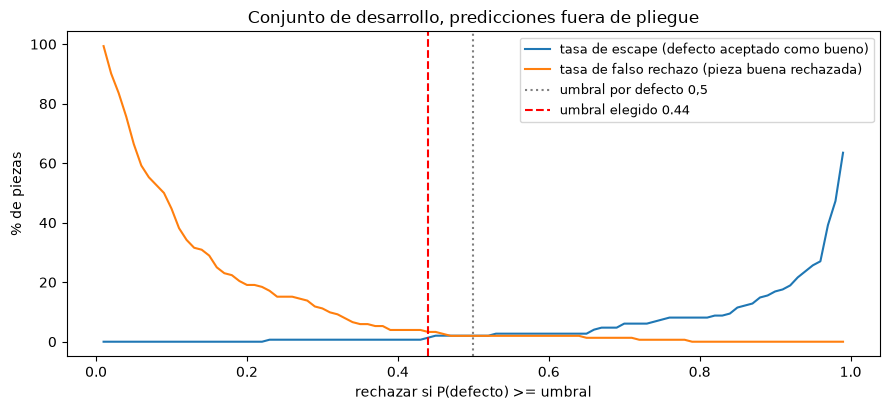

umbral 0.50: tasa de escape 2.0%, tasa de falso rechazo 2.0%
umbral 0.44: tasa de escape 1.4%, tasa de falso rechazo 3.3%


In [11]:
def rates(p_defect, is_defect, t):
    reject = p_defect >= t
    return np.mean(~reject[is_defect]), np.mean(reject[~is_defect])     # tasa de escape, tasa de falso rechazo

p_dev = 1 - oof_ft_tta[:, 0]
is_def_dev = labels[dev] > 0
grid = np.linspace(0.01, 0.99, 99)
esc, fr = np.array([rates(p_dev, is_def_dev, t) for t in grid]).T
TARGET = 0.02
THRESH = grid[esc <= TARGET].max()

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(grid, esc * 100, label="tasa de escape (defecto aceptado como bueno)")
ax.plot(grid, fr * 100, label="tasa de falso rechazo (pieza buena rechazada)")
ax.axvline(0.5, color="grey", ls=":", label="umbral por defecto 0,5")
ax.axvline(THRESH, color="red", ls="--", label=f"umbral elegido {THRESH:.2f}")
ax.set_xlabel("rechazar si P(defecto) >= umbral"); ax.set_ylabel("% de piezas"); ax.legend(fontsize=9)
ax.set_title("Conjunto de desarrollo, predicciones fuera de pliegue"); plt.tight_layout(); plt.show()
for t in (0.5, THRESH):
    e, f = rates(p_dev, is_def_dev, t)
    print(f"umbral {t:.2f}: tasa de escape {e:.1%}, tasa de falso rechazo {f:.1%}")

Con el umbral por defecto de 0,50 se escapa el 2,0 % de las fotos defectuosas de desarrollo (3 de 148), justo por encima del objetivo del 2 %. Bajar el umbral a 0,44 reduce los escapes al 1,4 % (2 de 148) y sube los falsos rechazos del 2,0 % al 3,3 % (de 3 a 5 de 152 piezas buenas). Las curvas son planas entre ambos valores porque la mayoría de las fotos reciben probabilidades seguras; solo unas pocas quedan en medio.

Ten presente la resolución de los datos: con 148 fotos defectuosas, cada una vale 0,7 puntos porcentuales de tasa de escape, así que un objetivo del 2 % está cerca de lo que este conjunto de datos puede medir. Una línea real fijaría el umbral con miles de piezas y lo revisaría a medida que se acumulan datos.

## 11. Abrir el conjunto de prueba: la clasificación final

Todas las decisiones están ya congeladas: los modelos, el ensamblado, el umbral. Es el momento de puntuar el conjunto de prueba, una sola vez.

In [12]:
rows = []
for name, r in leaderboard.items():
    rows.append((name, r["cv"], macro_f1(labels[test], r["test"].argmax(1)), r["note"]))
print(f"{'modelo':52s} {'macro-F1 VC':>12s} {'macro-F1 PRUEBA':>16s}")
for name, cv, te, note in rows:
    print(f"{name:52s} {cv:12.3f} {te:14.3f}   {note}")

# ¿cuánto de la distancia entre modelos es suerte? se remuestrean las 100 fotos de prueba con reemplazo
rng = np.random.default_rng(0)
boot = rng.integers(0, len(test), size=(2000, len(test)))
def boot_f1(proba): return np.array([macro_f1(labels[test][b], proba[b].argmax(1)) for b in boot])
print(f"\n{'bootstrap sobre las fotos de prueba':52s} {'intervalo del 90%':>27s}")
scores = {}
for name, r in leaderboard.items():
    scores[name] = boot_f1(r["test"])
    lo, hi = np.percentile(scores[name], [5, 95])
    print(f"{name:52s} {lo:12.3f} - {hi:.3f}")
diff = scores["ResNet-18 ajustada, ensamblado de 5 modelos + TTA"] - scores["ResNet-18 congelada + regresión logística"]
print(f"ensamblado menos ResNet-18 congelada: intervalo del 90% {np.percentile(diff, 5):+.3f} a {np.percentile(diff, 95):+.3f}, "
      f"ensamblado por delante en el {np.mean(diff > 0):.0%} de los remuestreos")

final = test_ens.argmax(1)
print("\nmodelo final, matriz de confusión de prueba (filas = verdad, columnas = predicción):")
print("            " + "  ".join(f"{c:>7s}" for c in CLASSES))
for c, row in zip(CLASSES, confusion_matrix(labels[test], final)):
    print(f"{c:10s}  " + "  ".join(f"{v:7d}" for v in row))

is_def_test = labels[test] > 0
for t in (0.5, THRESH):
    e, f = rates(1 - test_ens[:, 0], is_def_test, t)
    print(f"aceptar/rechazar con umbral {t:.2f}: escapes {e:.1%} ({int(round(e * is_def_test.sum()))} de {is_def_test.sum()} defectuosas), "
          f"falsos rechazos {f:.1%} ({int(round(f * (~is_def_test).sum()))} de {(~is_def_test).sum()} buenas)")

modelo                                                macro-F1 VC  macro-F1 PRUEBA
clase mayoritaria                                           0.224          0.225   
características hechas a mano + regresión logística         0.644          0.678   
ResNet-18 congelada + regresión logística                   0.757          0.803   
ResNet-18 ajustada (modelo de un pliegue)                   0.776          0.714   
ResNet-18 ajustada, ensamblado de 5 modelos + TTA           0.777          0.788   columna VC: un modelo + TTA

bootstrap sobre las fotos de prueba                            intervalo del 90%


clase mayoritaria                                           0.200 - 0.247


características hechas a mano + regresión logística         0.585 - 0.760


ResNet-18 congelada + regresión logística                   0.716 - 0.879


ResNet-18 ajustada (modelo de un pliegue)                   0.624 - 0.794


ResNet-18 ajustada, ensamblado de 5 modelos + TTA           0.695 - 0.866
ensamblado menos ResNet-18 congelada: intervalo del 90% -0.084 a +0.052, ensamblado por delante en el 35% de los remuestreos

modelo final, matriz de confusión de prueba (filas = verdad, columnas = predicción):
               Good     Nick  Scratch
Good             47        0        4
Nick              0        7        5
Scratch           0        5       32
aceptar/rechazar con umbral 0.50: escapes 0.0% (0 de 49 defectuosas), falsos rechazos 7.8% (4 de 51 buenas)
aceptar/rechazar con umbral 0.44: escapes 0.0% (0 de 49 defectuosas), falsos rechazos 9.8% (5 de 51 buenas)


La revelación trae una sorpresa, y es la lección más útil del proyecto. El modelo ajustado individual cae de 0,776 en validación cruzada a 0,714 en el conjunto de prueba, mientras que las características congeladas suben de 0,757 a 0,803 y terminan por delante de nuestra solución final, el ensamblado (0,788). En las competiciones esto se conoce como **reordenación de la clasificación** (*leaderboard shake-up*).

El bootstrap muestra por qué ocurrió. Al remuestrear las 100 fotos de prueba, cada modelo obtiene un intervalo del 90 % de unos 0,17 de ancho, y la diferencia entre el ensamblado y las características congeladas va de −0,084 a +0,052, con el ensamblado por delante en solo el 35 % de los remuestreos. Con 12 mellas en el conjunto de prueba, una mella más o menos bien clasificada mueve la macro-F1 dos o tres puntos. Este conjunto de prueba no puede distinguir esos dos modelos. Lo que sí puede decir es que ambos son mucho mejores que la clase mayoritaria y, muy probablemente, mejores que las características hechas a mano, cuyo intervalo solo se solapa con los suyos en su extremo superior.

¿Deberíamos cambiar ahora al modelo de características congeladas? No. Elegir al ganador *por su puntuación de prueba* convertiría el conjunto de prueba en un conjunto de desarrollo más, y la puntuación que publicamos pasaría a ser una estimación optimista en lugar de honesta. El proceso (elegir con validación cruzada, informar con el conjunto de prueba bloqueado) es lo que hace fiable el número, aunque no sea el número que esperábamos.

Para la línea, el resultado es una buena noticia: con cualquiera de los dos umbrales, **ninguna de las 49 piezas defectuosas de prueba se habría enviado**. El precio son 4 o 5 piezas buenas rechazadas de 51 (7,8 % o 9,8 %), más que la estimación de desarrollo del 3,3 %; con 51 piezas buenas, cada una vale 2 puntos.

## 12. ¿Dónde mira el modelo y en qué se equivoca?

Una puntuación alta no basta para confiar en un modelo en una línea de producción: queremos saber que rechaza piezas *por el defecto*, no por algo que casualmente se correlaciona con los defectos en este conjunto de datos (la iluminación del día en que se fotografiaron los álabes rayados, un utillaje visible al fondo...). Ese fallo se llama **aprendizaje por atajos**, y es frecuente en conjuntos de datos industriales recogidos por lotes.

**Grad-CAM** (Selvaraju et al., 2017) permite echar un vistazo rápido. Se toman los últimos mapas de características convolucionales de la red (`layer4`, 7×7 posiciones × 512 canales), se pondera cada canal por cuánto aumenta la puntuación de la clase predicha cuando ese canal aumenta (su gradiente medio), se suman y se conserva la parte positiva. El resultado es un mapa aproximado de las regiones que empujaron la decisión hacia esa clase, ampliado sobre la foto.

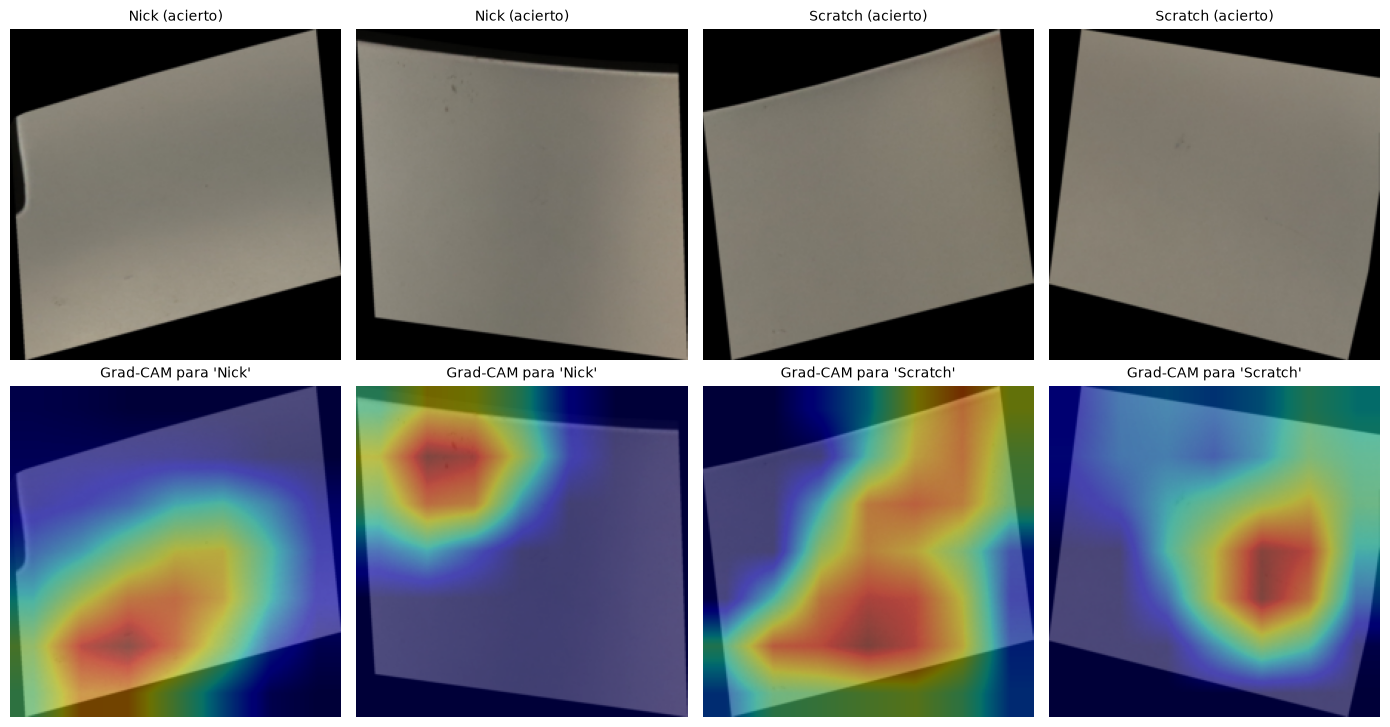

14 de 100 fotos de prueba mal clasificadas:
  verdad Nick     -> predicción Scratch    P(Good, Nick, Scratch) = (0.01, 0.24, 0.75)
  verdad Nick     -> predicción Scratch    P(Good, Nick, Scratch) = (0.08, 0.10, 0.81)
  verdad Nick     -> predicción Scratch    P(Good, Nick, Scratch) = (0.19, 0.24, 0.58)
  verdad Scratch  -> predicción Nick       P(Good, Nick, Scratch) = (0.00, 0.87, 0.13)
  verdad Good     -> predicción Scratch    P(Good, Nick, Scratch) = (0.25, 0.21, 0.54)
  verdad Scratch  -> predicción Nick       P(Good, Nick, Scratch) = (0.42, 0.46, 0.12)
  verdad Good     -> predicción Scratch    P(Good, Nick, Scratch) = (0.16, 0.37, 0.47)
  verdad Good     -> predicción Scratch    P(Good, Nick, Scratch) = (0.38, 0.21, 0.41)
  verdad Scratch  -> predicción Nick       P(Good, Nick, Scratch) = (0.01, 0.61, 0.39)
  verdad Nick     -> predicción Scratch    P(Good, Nick, Scratch) = (0.05, 0.21, 0.74)
  verdad Scratch  -> predicción Nick       P(Good, Nick, Scratch) = (0.02, 0.85, 0.13)

In [13]:
def grad_cam(model, x, cls):
    feats = {}
    h1 = model.layer4.register_forward_hook(lambda m, i, o: feats.__setitem__("a", o))
    h2 = model.layer4.register_full_backward_hook(lambda m, gi, go: feats.__setitem__("g", go[0]))
    model.zero_grad()
    model(x)[0, cls].backward()
    h1.remove(); h2.remove()
    w = feats["g"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * feats["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear")[0, 0].detach().numpy()
    return cam / (cam.max() + 1e-8)

model = fold_models[0]
for p in model.parameters(): p.requires_grad = True
pred_test = test_ens.argmax(1)
correct = [i for i in range(len(test)) if pred_test[i] == labels[test[i]]]
show = [i for i in correct if labels[test[i]] == 1][:2] + [i for i in correct if labels[test[i]] == 2][:2]   # dos mellas, dos arañazos
wrong = [i for i in range(len(test)) if pred_test[i] != labels[test[i]]]
fig, axes = plt.subplots(2, 4, figsize=(14, 7.4))
for j, i in enumerate(show):
    x = XN[test[i]:test[i] + 1]
    cam = grad_cam(model, x, int(pred_test[i]))
    axes[0, j].imshow(X[test[i]]); axes[0, j].set_title(f"{CLASSES[labels[test[i]]]} (acierto)", fontsize=10)
    axes[1, j].imshow(X[test[i]]); axes[1, j].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, j].set_title(f"Grad-CAM para '{CLASSES[pred_test[i]]}'", fontsize=10)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

print(f"{len(wrong)} de {len(test)} fotos de prueba mal clasificadas:")
for i in wrong:
    p = test_ens[i]
    print(f"  verdad {CLASSES[labels[test[i]]]:8s} -> predicción {CLASSES[pred_test[i]]:8s}   "
          f"P(Good, Nick, Scratch) = ({p[0]:.2f}, {p[1]:.2f}, {p[2]:.2f})")

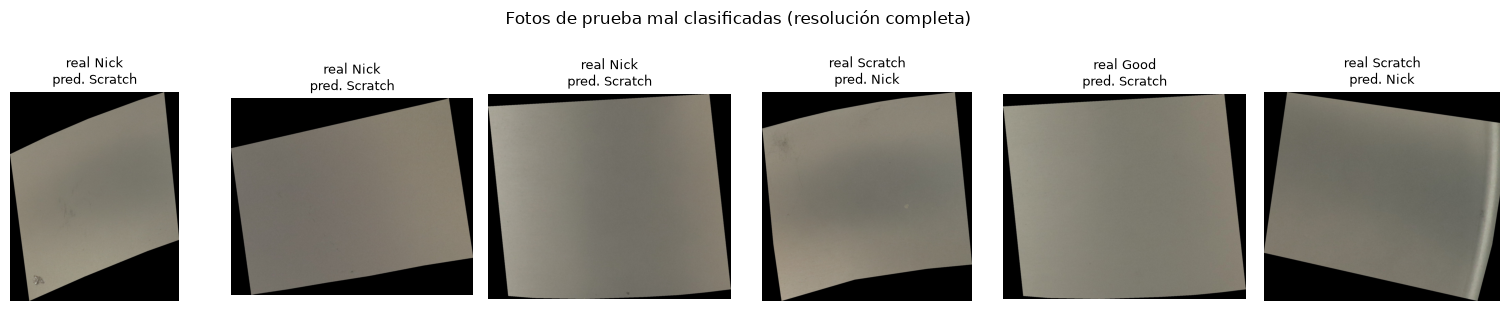

In [14]:
if wrong:
    n = min(len(wrong), 6)
    fig, axes = plt.subplots(1, n, figsize=(2.6 * n, 3.0), squeeze=False)
    for ax, i in zip(axes[0], wrong[:n]):
        ax.imshow(Image.open(files[test[i]])); ax.axis("off")
        ax.set_title(f"real {CLASSES[labels[test[i]]]}\npred. {CLASSES[pred_test[i]]}", fontsize=9)
    plt.suptitle("Fotos de prueba mal clasificadas (resolución completa)", y=1.02); plt.tight_layout(); plt.show()

Los mapas de calor son bastos (cada celda de la cuadrícula de 7×7 cubre 32×32 píxeles). En la segunda foto de mella, el punto caliente cae sobre las marcas oscuras visibles arriba a la izquierda, y en la última foto de arañazo, sobre una marca tenue a la derecha del centro: ahí el modelo está mirando el defecto. En las otras dos fotos el mapa es amplio y se extiende hacia el borde inferior del álabe, así que demuestran menos. Grad-CAM es una comprobación de sentido común, no una prueba: a 224×224 píxeles, la mayoría de los defectos tienen solo uno o dos píxeles de ancho, y un proyecto real miraría muchos más mapas, también los de las piezas buenas.

La lista de errores cuenta una historia coherente. De las 14 equivocaciones, 10 intercambian una mella y un arañazo. Las otras 4 son álabes buenos clasificados como Scratch, todos con una probabilidad de Good entre 0,16 y 0,38: casos dudosos, justo los que el reparto en tres vías de abajo envía a una persona. Ningún álabe defectuoso se clasificó como Good. Incluso en las fotos a resolución completa de arriba, los defectos cuestan de encontrar a simple vista, lo que muestra cuánto detalle pierde la versión de 224×224. Con solo 48 mellas en total, conseguir más fotos de mellas (y revisar las etiquetas de las que confunden) es el siguiente paso más valioso, por delante de cualquier cambio en el modelo.

## 13. Del notebook a la línea de producción

Una competición termina con la clasificación. Un proyecto real de inspección apenas empieza. Las preguntas que deciden si el modelo se usa:

* **Velocidad.** La línea necesita una respuesta antes de que llegue la siguiente pieza. La celda de abajo mide el tiempo del modelo en esta CPU.
* **Qué hacer con las piezas dudosas.** Las probabilidades dan un reparto natural en tres vías: lo que es Good con seguridad se envía, lo que es defecto con seguridad se rechaza y todo lo intermedio va al inspector humano. La carga del inspector se reduce a la fracción dudosa, y cada una de esas decisiones se convierte en un nuevo ejemplo etiquetado.
* **Más datos donde duele.** Con solo 48 mellas, cada foto de mella adicional vale mucho más que otra foto buena. El análisis de errores (sección 12) indica qué tipo de foto conviene recoger a continuación.
* **Deriva.** Una cámara nueva, otra luz, un nuevo proveedor de materia prima: cualquiera de estas cosas puede cambiar las fotos en silencio. Registra la P(defecto) media del modelo y la proporción de piezas dudosas por turno; un cambio brusco es la primera señal de que hay que revisar el modelo.
* **Resolución.** Tiramos el 95 % de los píxeles para encajar en 224×224. Cortar cada foto en teselas a resolución completa, o detectar los defectos con un modelo de segmentación (notebook 09) en lugar de clasificar fotos enteras, son los pasos naturales cuando el análisis de errores muestra que se escapan defectos pequeños.

In [15]:
one = XN[:1]
with torch.no_grad():
    for _ in range(3): model(one)                                     # calentamiento
    t0 = time.time(); [model(one) for _ in range(20)]; single = (time.time() - t0) / 20
t0 = time.time(); predict(model, np.array([0]), tta=True); tta_time = time.time() - t0
size_mb = sum(p.numel() for p in model.parameters()) * 4 / 1e6
print(f"un modelo, una foto: {single * 1000:.0f} ms;  con TTA de 8 vistas: {tta_time * 1000:.0f} ms;  "
      f"ensamblado de 5 modelos + TTA: unos {5 * tta_time:.1f} s por foto")
print(f"tamaño: {size_mb:.0f} MB por modelo (float32)")

p_def = 1 - test_ens[:, 0]
low, high = 0.15, 0.85
auto_good, auto_reject = p_def < low, p_def >= high
doubtful = ~auto_good & ~auto_reject
print(f"\nreparto en tres vías de las {len(test)} piezas de prueba (P(defecto) < {low} se envía, >= {high} se rechaza, si no, a una persona):")
print(f"  enviadas automáticamente:   {auto_good.sum():3d}, de ellas defectuosas: {(auto_good & is_def_test).sum()}")
print(f"  rechazadas automáticamente: {auto_reject.sum():3d}, de ellas buenas: {(auto_reject & ~is_def_test).sum()}")
print(f"  enviadas al inspector:      {doubtful.sum():3d} ({doubtful.mean():.0%} de la carga de trabajo)")

un modelo, una foto: 66 ms;  con TTA de 8 vistas: 471 ms;  ensamblado de 5 modelos + TTA: unos 2.4 s por foto
tamaño: 45 MB por modelo (float32)

reparto en tres vías de las 100 piezas de prueba (P(defecto) < 0.15 se envía, >= 0.85 se rechaza, si no, a una persona):
  enviadas automáticamente:    28, de ellas defectuosas: 0
  rechazadas automáticamente:  43, de ellas buenas: 0
  enviadas al inspector:       29 (29% de la carga de trabajo)


Un modelo responde en bastante menos de una décima de segundo por foto en la CPU de un portátil, lo bastante rápido para una línea que produce una pieza cada pocos segundos. El ensamblado completo con TTA de 8 vistas tarda unos 3 segundos por foto, lo que puede no encajar en el tiempo de ciclo; como el TTA no aportó nada medible, un equipo pondría en producción los cinco modelos sin TTA (cinco veces un modelo) o un solo modelo en un pequeño ordenador de borde.

El reparto en tres vías es donde el modelo se amortiza. De las 100 piezas de prueba, 71 se deciden automáticamente **sin ningún error** (28 enviadas, 43 rechazadas) y 29 van al inspector. En esta muestra eso supone recortar un 71 % la carga del inspector, y los casos dudosos los sigue viendo una persona. Las bandas (0,15 y 0,85) se fijaron a mano aquí; en un proyecto real se elegirían con el conjunto de desarrollo, igual que el umbral de la sección 10.

## Ideas clave

* **Fija la métrica y bloquea el conjunto de prueba antes de empezar.** Macro-F1 para el problema desbalanceado de tres clases, tasas de escape y de falso rechazo para la decisión que de verdad toma la línea. Cada elección se hizo con validación cruzada; el conjunto de prueba se puntuó una sola vez.
* **Supera siempre una referencia.** "Siempre Good" y las características hechas a mano marcaron el suelo y dijeron lo difícil que es realmente el problema.
* **Con unos pocos cientos de imágenes reales, gana el aprendizaje por transferencia.** Una red entrenada desde cero no pudo aprender lo suficiente con 240 fotos; las características de ImageNet funcionaron sin más, y el ajuste fino de las capas superiores con aumento de datos las mejoró en validación cruzada.
* **Los trucos de competición son baratos**: los modelos de los pliegues de validación cruzada se convierten gratis en un ensamblado, y el aumento en tiempo de prueba aprovecha una simetría del problema (la orientación no importa). Mide si ayudan: aquí el TTA no aportó nada.
* **Un conjunto de prueba pequeño es ruidoso.** Con 100 fotos, diferencias de unos pocos puntos de macro-F1 entre modelos están dentro del ruido; el bootstrap lo hace visible. No cambies de modelo después de mirar la prueba.
* **Una probabilidad no es una decisión.** El umbral de rechazo codifica lo que cuesta cada error, y el mismo modelo puede ajustarse para tener pocos escapes o pocos falsos rechazos, o enviar las piezas dudosas a una persona.
* **Mira lo que mira el modelo.** Grad-CAM y la lista de errores son la forma de encontrar atajos, errores de etiquetado y los datos que conviene recoger a continuación.

## Ejercicios

1. Cambia `R` a 160 y a 288 (la celda de ajuste fino tarda aproximadamente el doble a 288). ¿Cómo reacciona la macro-F1 con validación cruzada? ¿Qué clase se beneficia más de tener más píxeles?
2. Recorta cada foto al rectángulo que contiene el álabe (los píxeles con brillo mayor que 40) antes de redimensionarla. ¿Ayuda usar los píxeles del álabe en lugar del fondo negro?
3. Descongela también `layer2` y después ajusta todas las capas. Compara las puntuaciones con validación cruzada y el tiempo de entrenamiento. ¿A partir de qué punto adaptar más pesos empieza a perjudicar con tan pocos datos?
4. Quita los pesos de clase de la pérdida. ¿Qué le pasa a la columna Nick de la matriz de confusión?
5. Fija el objetivo de tasa de escape en el 0 % en el conjunto de desarrollo. ¿Qué le hace eso a la tasa de falso rechazo, y lo estable que es ese umbral en el conjunto de prueba?
6. Sustituye ResNet-18 por `torchvision.models.mobilenet_v3_small` (preentrenada). ¿Cuánto más rápida es por foto y cuánta exactitud cuesta?
7. Combina modelos: promedia las probabilidades de la regresión logística sobre características congeladas y del ensamblado ajustado. ¿Es la combinación mejor que cada uno por separado en validación cruzada?